# Notebook 08 — Policy scenario testing

Applies the **frozen** calibrated model ($\pi^*$, $t^*$) to counterfactual network changes: each City of
Sydney *planned regional* cycle corridor is upgraded to LTS 1, the low-stress class is re-routed on the
upgraded network, and the change in low-stress connectivity and re-routed demand is reported (thesis
Discussion; Table `tab:scenario_lts`, Appendix G).

**Inputs:** the frozen Stage-3 outputs (`stage3_final.json`, `od_final_t.csv`, `A_low.npz`, `A_high.npz`)
and the CoS bike-network shapefile (`Shape File.zip`). **Outputs:** the per-scenario `fig_*` flow / time /
LTS figures, `policy_regional_planned_summary.csv`, the diagnostic route maps, and the `tab:scenario_lts`
LTS-connectivity table printed at the end.

**Setup:** the three cells below reconstruct the same context the report-figures notebook uses (network,
frozen demand, cached path stores) so this notebook runs on its own. They are quick — `route_store` reuses
the on-disk path cache. The corridor re-routing is the only slow step if you re-execute end to end.


## Setup — load the frozen model and cached routing context

Load the frozen $(\pi^*, t^*)$, the per-stage flows and monitored-link geometry, the network and cordon,
and the cached $k$-shortest path stores — the shared basis every scenario re-routes against.


In [ ]:
import json, warnings
import numpy as np, pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patheffects import withStroke
import geopandas as gpd, osmnx as ox, networkx as nx
from scipy import sparse
import thesis_common as tc



tc.set_style()
HALO = [withStroke(linewidth=2.6, foreground="white")]
R1_INCLUDE_STAGE2 = True     # R1 as 4 panels (seed, Stage 1, Stage 2, Stage 3); False -> 3 panels
RUN_POLICY = True            # scenario figure (re-routes the low-stress class; slow)
POLICY_CORRIDOR = ["Oxford Street", "King Street"]
N_JOBS = 1                   # path stores are cached by Notebook 05; only the policy scenario re-routes
NUM = []                     # lines for results_numbers.txt
def say(s=""):
    print(s); NUM.append(s)

In [3]:
final  = tc.read_final()
pi_star = final["pi_star"]
cal    = pd.read_csv(tc.DATA_PROCESSED / "od_final_t.csv").sort_values("pair_idx").reset_index(drop=True)
links  = pd.read_csv(tc.DATA_PROCESSED / "A_neutral_links.csv").sort_values("link_idx").reset_index(drop=True)
fit    = pd.read_csv(tc.DATA_PROCESSED / "stage3_link_fit.csv").sort_values("link_idx").reset_index(drop=True)
snap   = pd.read_csv(tc.DATA_PROCESSED / "count_link_snap.csv")
A_low  = sparse.load_npz(tc.DATA_PROCESSED / "A_low.npz").tocsr()
A_high = sparse.load_npz(tc.DATA_PROCESSED / "A_high.npz").tocsr()
A_neu  = sparse.load_npz(tc.DATA_PROCESSED / "A_neutral.npz").tocsr()
L, P = len(links), len(cal)
v_obs  = links["v_obs"].to_numpy(float)
n_seed, t_cal, t_star = (cal[c].to_numpy(float) for c in ("n_seed", "t", "t_final"))
train  = tc.load_train_mask(L)
test   = fit["split"].eq("test").to_numpy()        # split recorded by NB07's single evaluation
assert (test == ~train).all(), "split in stage3_link_fit.csv disagrees with train_mask.npy"
assert abs(t_star.sum() - final["t_star_sum"]) < 1e-6, "od_final_t.csv does not match the frozen t*"
PI0 = tc.PI_LOW0

f = {  # modelled flow on monitored links, per stage
    "seed":   np.asarray(A_neu.dot(n_seed)).ravel(),
    "stage1": np.asarray(A_neu.dot(t_cal)).ravel(),
    "stage2": tc.flow(A_low, A_high, PI0, t_cal),
    "stage3": tc.flow(A_low, A_high, pi_star, t_star),
}
M = {k: tc.metrics(v[train], v_obs[train]) for k, v in f.items()}
M["stage3_test"] = tc.metrics(f["stage3"][test], v_obs[test])
assert np.allclose(f["stage3"], fit["f_final"]), "flows differ from NB07 - re-run NB07"

# geometry: one projected point per monitored link + names
names = tc.link_names(links, snap)
geo = snap.merge(links[["link_idx", "u", "v", "k"]], on=["u", "v", "k"]).groupby("link_idx").agg(lon=("lon", "mean"), lat=("lat", "mean"))
pts = gpd.GeoSeries(gpd.points_from_xy(geo.lon, geo.lat), crs=tc.LONLAT_CRS).to_crs(tc.PROJECTED_CRS)
sx = pd.Series(pts.x.values, index=geo.index).reindex(range(L)).to_numpy()
sy = pd.Series(pts.y.values, index=geo.index).reindex(range(L)).to_numpy()
label = np.array([names.get(i, (f"link {i}", None))[0] for i in range(L)], dtype=object)

Gr = tc.load_network(); tc.set_costs(Gr, lam=tc.STRESS_PENALTY)
edges = ox.graph_to_gdfs(Gr, nodes=False).reset_index()
cordon = gpd.read_file(tc.STUDY_AREA_CORDON).to_crs(tc.PROJECTED_CRS)
cx0, cy0, cx1, cy1 = cordon.total_bounds
print(f"pi* = {pi_star:.2f} | L={L} ({int(train.sum())} train / {int(test.sum())} held-out) | P={P:,}")

def place_labels(ax, xs, ys, texts, fs=8, color="black"):
    """Annotate points, choosing for each label the offset direction farthest from labels
    already placed (simple overlap avoidance; works in data units)."""
    x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim(); dx, dy = 0.02 * (x1 - x0), 0.025 * (y1 - y0)
    opts = [(dx, dy, "left", "bottom"), (dx, -dy, "left", "top"), (-dx, dy, "right", "bottom"),
            (-dx, -dy, "right", "top"), (0, 2.2 * dy, "center", "bottom"), (0, -2.2 * dy, "center", "top")]
    placed = []
    for x, y, t in zip(xs, ys, texts):
        def score(o):
            px, py = x + o[0] * 3, y + o[1] * 1.5
            return min([np.hypot((px - a) / (x1 - x0), (py - b) / (y1 - y0)) for a, b in placed] + [9])
        o = max(opts, key=score)
        px, py = x + o[0], y + o[1]
        placed.append((x + o[0] * 3, y + o[1] * 1.5))
        ax.annotate(t, (x, y), xytext=(px, py), textcoords="data", ha=o[2], va=o[3], fontsize=fs, color=color,
                    path_effects=HALO, zorder=9, arrowprops=dict(arrowstyle="-", color="#666", lw=0.6))

def basemap(ax, elow=False, lw=0.25):
    edges.plot(ax=ax, color=tc.COL["grid"], lw=lw, zorder=0)
    if elow:
        edges[edges["lts"] <= tc.LOW_STRESS_MAX_LTS].plot(ax=ax, color=tc.COL["elow"], lw=0.7, zorder=1)
def cordon_line(ax):
    cordon.boundary.plot(ax=ax, color=tc.COL["cordon"], lw=0.9, ls="--", zorder=2)
def frame(ax, pad=400):
    ax.set_xlim(cx0 - pad, cx1 + pad); ax.set_ylim(cy0 - pad, cy1 + pad)
    ax.set_aspect("equal"); ax.set_axis_off()

pi* = 0.64 | L=77 (53 train / 24 held-out) | P=1,850


In [4]:
# Build / load the cached k-shortest path stores (fast: route_store reuses the disk cache)
exp_pairs, assembly, rep_idx = tc.expand_pairs(cal)
store_high = tc.route_store(tc.to_simple(Gr, "cost_high"), exp_pairs, tc.K_STORE, "cost_high", tc.store_tag("high"), n_jobs=N_JOBS)
store_low  = tc.route_store(tc.to_simple(Gr, "cost_low"),  exp_pairs, tc.K_STORE, "cost_low",  tc.store_tag("low"),  n_jobs=N_JOBS)


  [high_beta0_grade_k5_sprd5] loaded cached path store (8,721 pairs, k=5)
  [low_lam2.4_beta0_grade_k5_sprd5] loaded cached path store (8,721 pairs, k=5)


## Scenario — upgrade each planned corridor to LTS 1 and re-route

Read the CoS bike-network shapefile, keep the *planned regional* segments, normalise their route codes,
and group them into individual and connected corridor scenarios. For each scenario the matched graph edges
are reclassified to LTS 1, the low-stress class is re-routed, and the flow change, travel-time impact and
LTS-before/after are drawn, with a per-scenario summary saved. The final cell reports the low-stress
connectivity gain (`tab:scenario_lts`) — this notebook's end-of-run key-results table.


In [5]:
import geopandas as gpd, pandas as pd, numpy as np, re, zipfile, tempfile
from pathlib import Path

# ── 1. read the CoS bike-network shapefile from the zip  ──────
_zip = tc.DATA_RAW / "Shape File.zip"
assert _zip.exists(), f"zip not found: {_zip}"
_tmp = tempfile.mkdtemp()
zipfile.ZipFile(_zip).extractall(_tmp)
_shp = next(p for p in Path(_tmp).rglob("*.shp"))
print("reading:", _zip.name, "->", _shp.name)

g = gpd.read_file(_shp).to_crs(tc.PROJECTED_CRS)          # -> EPSG:28356 (graph CRS)
print("rows:", len(g), "| columns:", list(g.columns))

# ── 2. find role/status columns by content (robust to field-name truncation) ──
def col_with(tokens):
    toks = [t.lower() for t in tokens]
    for c in g.columns:
        if c == "geometry": continue
        vals = " || ".join(str(x).lower() for x in g[c].dropna().unique())
        if any(t in vals for t in toks): return c
    raise KeyError(f"no column containing {tokens}; columns = {list(g.columns)}")

C_ROLE   = col_with(["regional network"])
C_STATUS = col_with(["planned"])
C_ROUTE  = [c for c in g.columns if c.lower().startswith("route")]
C_STREET = next((c for c in g.columns if c.lower() == "street"), None)
print(f"role={C_ROLE!r}  status={C_STATUS!r}  route={C_ROUTE}  street={C_STREET!r}")

# ── 3. filter: planned regional network ───────────────────────────────────────
role = g[C_ROLE].astype(str).str.upper()
stat = g[C_STATUS].astype(str).str.upper()
sel = g[role.str.contains("REGIONAL") & stat.str.contains("PLANNED")].copy()

# ── 4. normalise messy route labels to canonical codes (R1..R13, etc.) ────────
# merges 'R12 City Centre to Rose Bay', '11 Alexandria...', '14' -> R12/R11/R14;
# a comma'd label ('R4,R9') yields BOTH codes, so a shared segment joins both routes.
def parse_codes(row):
    codes = set()
    for c in C_ROUTE:
        if pd.notna(row.get(c)):
            for tok in str(row[c]).split(","):
                m = re.match(r'^\s*R?\s*(\d+[A-Za-z]?)\b', tok.strip())
                if m: codes.add("R" + m.group(1).upper())
    return sorted(codes)

sel["route_codes"] = sel.apply(parse_codes, axis=1)
def _primary(row):
    if row["route_codes"]: return row["route_codes"][0]
    r = " ".join(str(row.get(c) or "") for c in C_ROUTE)
    return "CityCentre" if "city centre" in r.lower() else "unassigned"
sel["route_key"] = sel.apply(_primary, axis=1)
sel["seg_km"]    = sel.geometry.length / 1000
sel["Street"]    = sel[C_STREET].astype(str) if C_STREET else ""

# ── 5. per-route summary (a shared segment counts once in each of its routes) ──
mem = [(c, r.seg_km, r.Street) for _, r in sel.iterrows()
       for c in (r.route_codes or [r.route_key])]
summ = (pd.DataFrame(mem, columns=["route", "km", "street"])
          .groupby("route").agg(segments=("km", "size"), km=("km", "sum"),
              streets=("street", lambda s: ", ".join(sorted({str(x) for x in s if pd.notna(x)})[:6])))
          .sort_values("km", ascending=False))
summ["km"] = summ["km"].round(2)
print(f"\nREGIONAL NETWORK & PLANNED: {len(sel)} segments, {sel.seg_km.sum():.2f} km\n")
print(summ.to_string())

# ── 6. write the GeoJSON the re-routing cell reads ────────────────────────────
out = sel[["route_key", "Street", "seg_km", "geometry"]].copy()
for c in ("StreetFrom", "StreetTo", "FacilityTy"):
    if c in sel.columns: out[c] = sel[c].astype(str)
out["route_codes"] = sel["route_codes"].apply(",".join)
out_fp = tc.DATA_PROCESSED / "regional_planned_routes.geojson"
out.to_file(out_fp, driver="GeoJSON")
summ.to_csv(tc.REPORTS / "regional_planned_route_summary.csv")
print(f"\nsaved -> {out_fp}  (CRS {out.crs})")

reading: Shape File.zip -> BikeNetwork_CityofSydney.shp
rows: 595 | columns: ['Route', 'Route2', 'Street', 'FacilityTy', 'RoadSide', 'StreetFrom', 'StreetTo', 'YearComple', 'Status', 'NetworkRol', 'SegmentDes', 'ID', 'GlobalID', 'Shape_Leng', 'geometry']
role='NetworkRol'  status='Status'  route=['Route', 'Route2']  street='Street'

REGIONAL NETWORK & PLANNED: 105 segments, 23.96 km

            segments    km                                                                        streets
route                                                                                                    
unassigned         9  4.80                   BROADWAY, DARLING DR, GOTTENHAM ST, HAY ST, LANG RD, PARK ST
R12               15  2.58                          BAYSWATER RD, CRAIGEND ST, KINGS CROSS RD, WILLIAM ST
R4                 9  2.20           ALEXANDRA DR, LYONS RD, MCEVOY ST, MISSENDEN RD, ODEA AV, SWANSON ST
R11                7  1.97      ALEXANDRA CANAL CYCLEWAY, GEORGE ST, HUNTLEY ST, O'


[START] Load planned route data
Source features: 105
Valid geometries: 105
Missing/empty geometries: 0
[DONE] Load planned route data — 0s

[START] Create raw planned-route diagnostic map

RAW ROUTE INVENTORY
-----------------------------------------------------------------
            source_features  geometry_length_m
route_code                                    
CityCentre                1          85.269476
R1                        7        1344.594481
R10                      10        1424.535908
R11                       7        1971.260583
R12                      15        2577.187561
R13                       5        1197.427369
R14                       4         712.737117
R15A                      1         378.237263
R19                       2         596.351142
R2                        2         296.635543
R23                       1         129.807912
R38                       2        1871.477827
R4                        9        2199.375704
R5                 

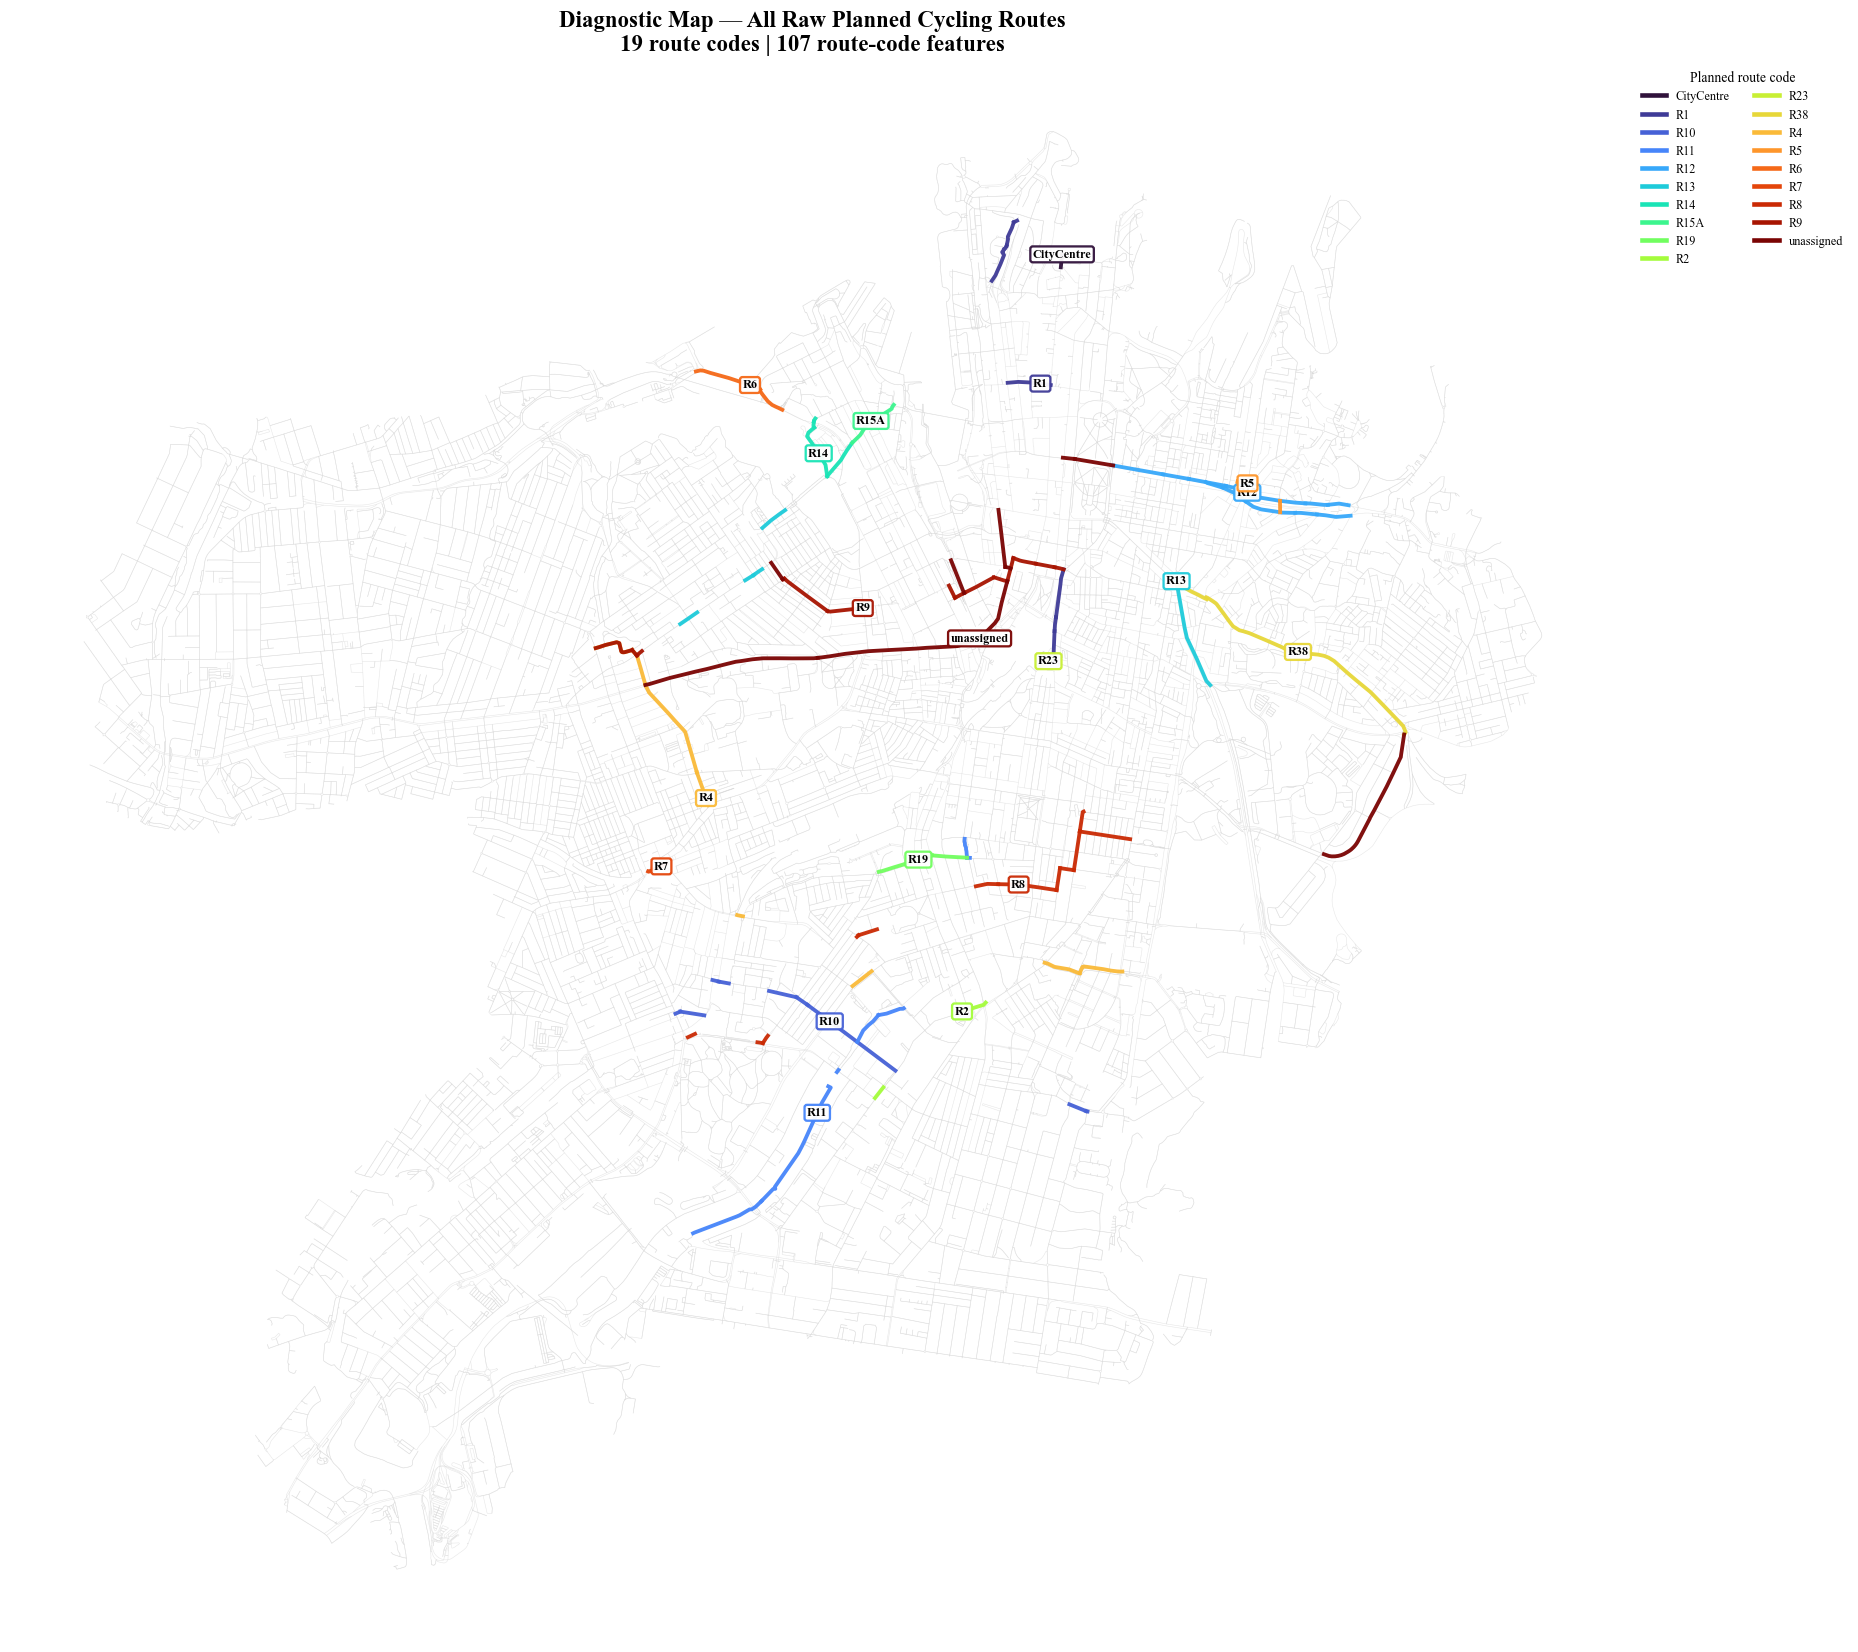

[DONE] Create raw planned-route diagnostic map — 7s

[START] Prepare graph edge geometries and LTS
[DONE] Prepare graph edge geometries and LTS — 0s

[START] Atomise planned route geometries

Route codes found:
CityCentre, R1, R10, R11, R12, R13, R14, R15A, R19, R2, R23, R38, R4, R5, R6, R7, R8, R9, unassigned
Total atomic route segments: 543
[DONE] Atomise planned route geometries — 0s

[START] Build route-segment connectivity graph
Connectivity graph: 543 nodes, 1054 connections
[DONE] Build route-segment connectivity graph — 0s

[START] Identify connected route components

CONNECTED COMPONENT DIAGNOSTICS
----------------------------------------------------------------------
  R11, R19: 0.74 km — below minimum length
  R12, R5, unassigned: 3.10 km — INCLUDED
  R1, R23, R4, R9, unassigned: 6.84 km — INCLUDED
  R10, R11: 1.39 km — INCLUDED
  R13, R38, unassigned: 3.64 km — INCLUDED
  R9, unassigned: 0.74 km — below minimum length
  R14, R15A: 1.09 km — INCLUDED

Multi-code components f

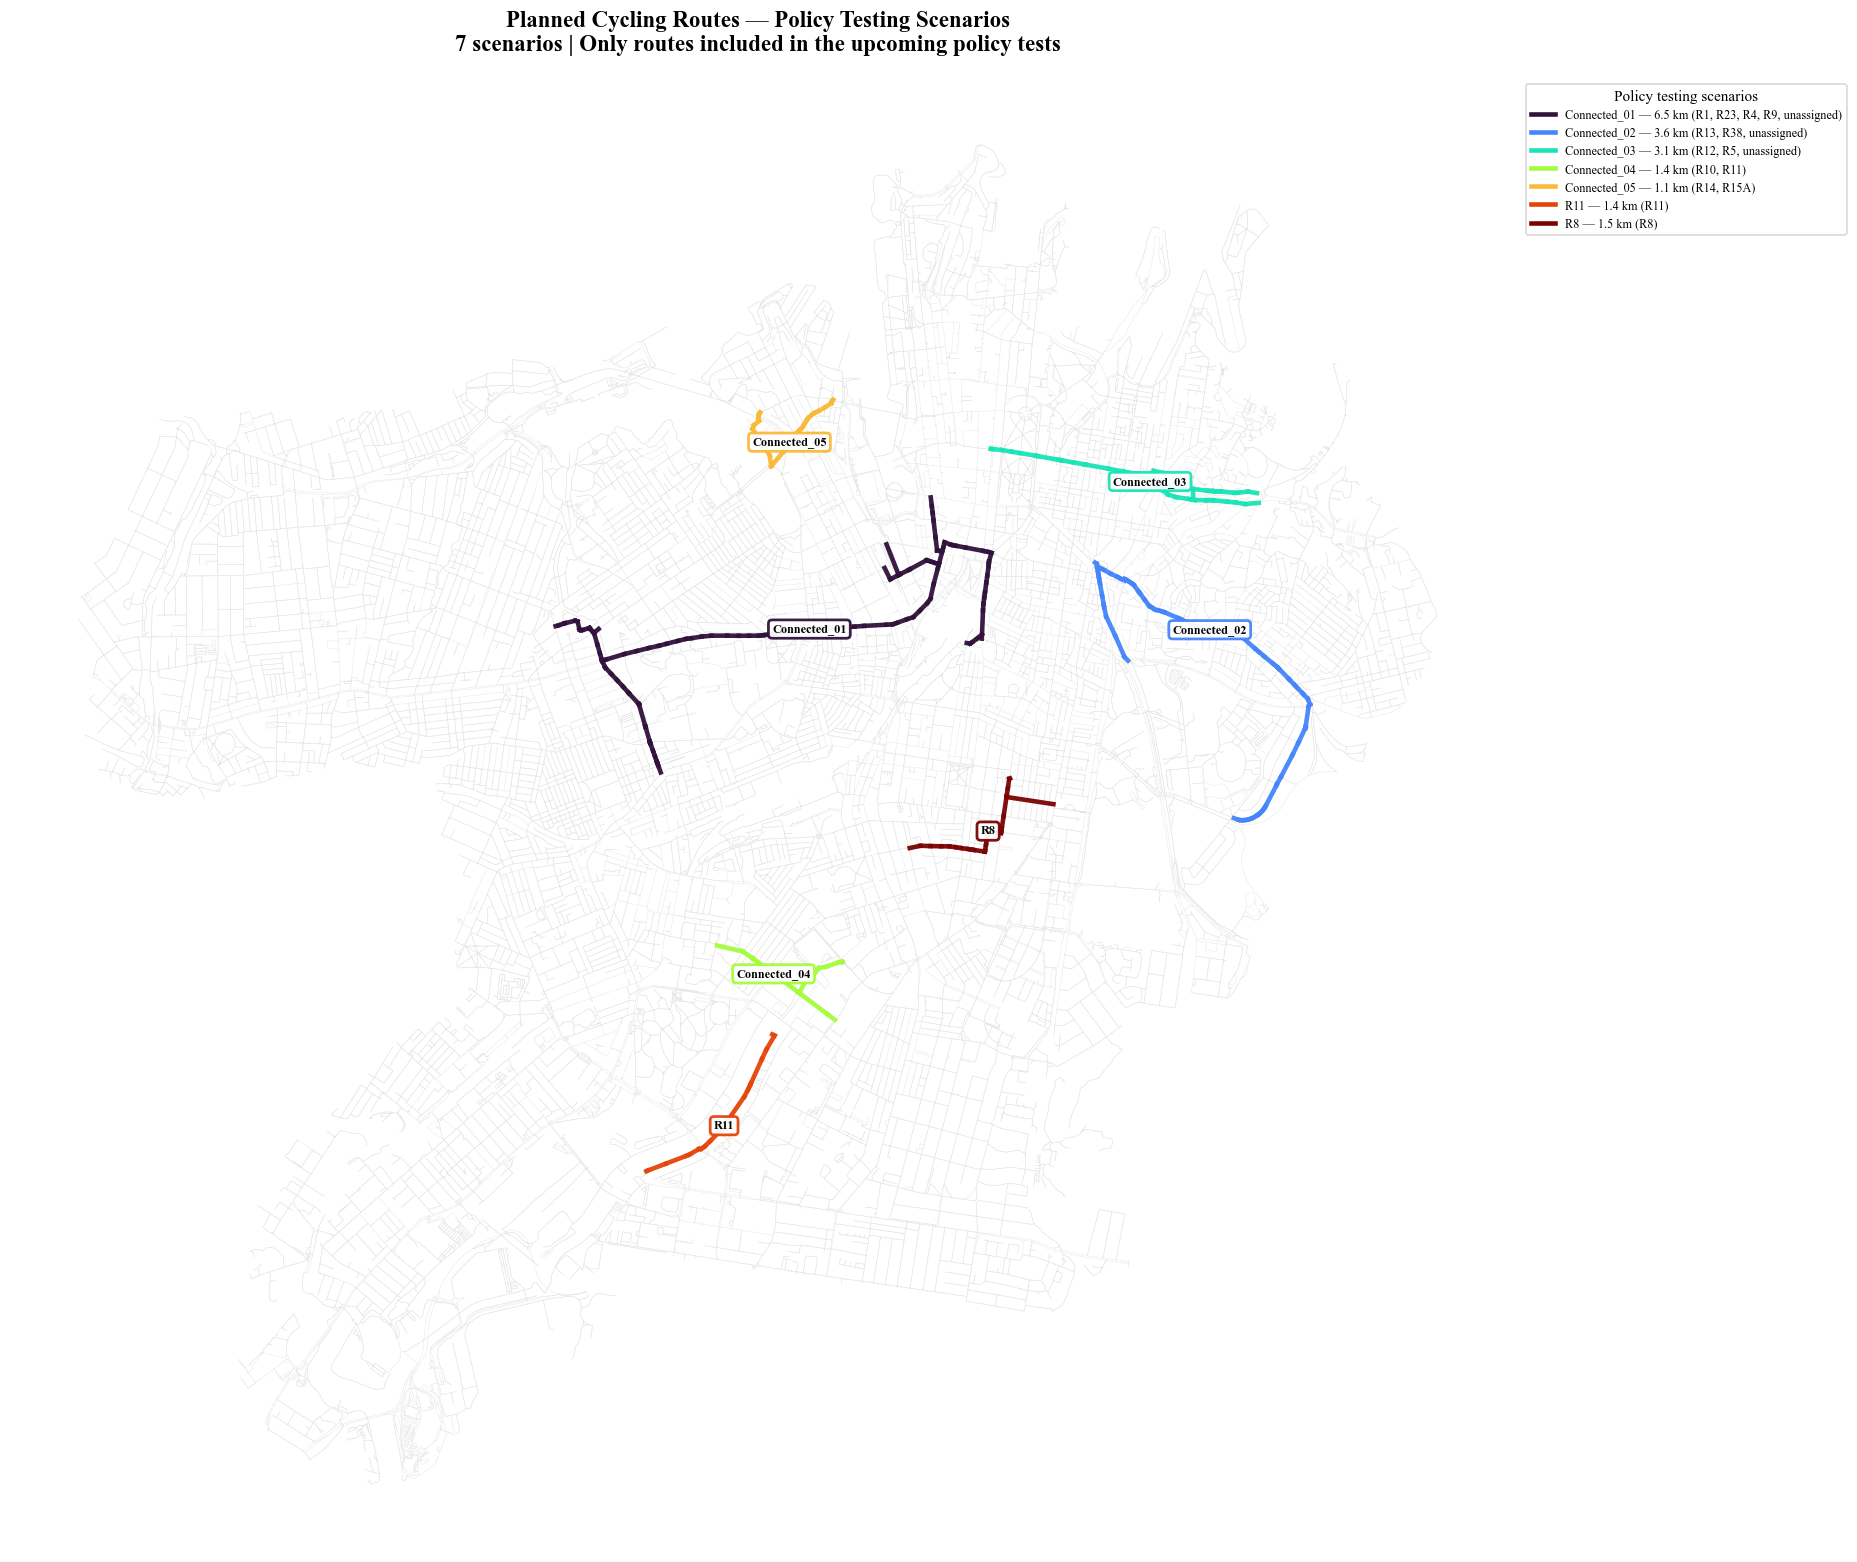


Policy testing route map saved to:
c:\Users\aylex\OneDrive - The University of Sydney (Students)\Thesis A\Python Code\Phase 1 + 2\reports\diagnostic_policy_testing_routes.png

[START] Prepare road-name lookup
[DONE] Prepare road-name lookup — 0s

[START] Load baseline route store
[ETA] Baseline route-store generation may take some time.
  [low_lam2.4_beta0_grade_k5_sprd5] loaded cached path store (8,721 pairs, k=5)
[DONE] Load baseline route store — 0s

Running 7 individual and connected scenarios:
  Connected_01
  Connected_02
  Connected_03
  Connected_04
  Connected_05
  R11
  R8

######################################################################
SCENARIO 1/7: Connected_01
######################################################################
[OVERALL ETA] Timing first scenario to establish an average runtime.

SCENARIO: Connected_01
[START] Matching planned route to graph edges
[TIME] Connected_01 — route matching: 0s elapsed
[INFO] Main road by matched distance: Broadway
[INF

C:\Users\aylex\AppData\Local\Temp\ipykernel_22672\3002194685.py:898: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  region = seg.geometry.unary_union.buffer(500)
C:\Users\aylex\AppData\Local\Temp\ipykernel_22672\3002194685.py:922: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  street: group.geometry.unary_union.representative_point()
C:\Users\aylex\AppData\Local\Temp\ipykernel_22672\3002194685.py:922: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  street: group.geometry.unary_union.representative_point()
C:\Users\aylex\AppData\Local\Temp\ipykernel_22672\3002194685.py:1039: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig3.subplots_adjust(bottom=0.16)


  saved report figure  fig_route_Connected_01_lts.pdf/.png
[TIME] Connected_01 — LTS figure: 10s elapsed

[SCENARIO COMPLETE] Connected_01
[TIME] Total scenario runtime: 1m 01s
[TIME BREAKDOWN] Matching: 0s | Policy store: 0s | Flow figure: 38s | Time figure: 2s | LTS figure: 10s
[ETA] Overall scenario execution: 1/7 completed | elapsed 1m 01s | estimated remaining 6m 06s

######################################################################
SCENARIO 2/7: Connected_02
######################################################################
[OVERALL ETA] Estimated remaining: 6m 06s (based on previous scenario runtimes)

SCENARIO: Connected_02
[START] Matching planned route to graph edges
[TIME] Connected_02 — route matching: 0s elapsed
[INFO] Main road by matched distance: Oxford Street
[INFO] Matched 227 graph edges (approximately 7.00 km)
[TIME] Connected_02 — apply policy costs: 0s elapsed
[INFO] Policy applied to 307 directed graph edges
[INFO] Policy route-store cache: policy_route_

C:\Users\aylex\AppData\Local\Temp\ipykernel_22672\3002194685.py:898: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  region = seg.geometry.unary_union.buffer(500)
C:\Users\aylex\AppData\Local\Temp\ipykernel_22672\3002194685.py:922: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  street: group.geometry.unary_union.representative_point()
C:\Users\aylex\AppData\Local\Temp\ipykernel_22672\3002194685.py:922: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  street: group.geometry.unary_union.representative_point()
C:\Users\aylex\AppData\Local\Temp\ipykernel_22672\3002194685.py:1039: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig3.subplots_adjust(bottom=0.16)


  saved report figure  fig_route_Connected_02_lts.pdf/.png
[TIME] Connected_02 — LTS figure: 7s elapsed

[SCENARIO COMPLETE] Connected_02
[TIME] Total scenario runtime: 1m 01s
[TIME BREAKDOWN] Matching: 0s | Policy store: 0s | Flow figure: 40s | Time figure: 2s | LTS figure: 7s
[ETA] Overall scenario execution: 2/7 completed | elapsed 2m 02s | estimated remaining 5m 07s

######################################################################
SCENARIO 3/7: Connected_03
######################################################################
[OVERALL ETA] Estimated remaining: 5m 07s (based on previous scenario runtimes)

SCENARIO: Connected_03
[START] Matching planned route to graph edges
[TIME] Connected_03 — route matching: 0s elapsed
[INFO] Main road by matched distance: William Street
[INFO] Matched 222 graph edges (approximately 5.32 km)
[TIME] Connected_03 — apply policy costs: 0s elapsed
[INFO] Policy applied to 295 directed graph edges
[INFO] Policy route-store cache: policy_route_C

C:\Users\aylex\AppData\Local\Temp\ipykernel_22672\3002194685.py:898: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  region = seg.geometry.unary_union.buffer(500)
C:\Users\aylex\AppData\Local\Temp\ipykernel_22672\3002194685.py:922: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  street: group.geometry.unary_union.representative_point()
C:\Users\aylex\AppData\Local\Temp\ipykernel_22672\3002194685.py:922: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  street: group.geometry.unary_union.representative_point()
C:\Users\aylex\AppData\Local\Temp\ipykernel_22672\3002194685.py:1039: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig3.subplots_adjust(bottom=0.16)


... (7 outputs left out)

C:\Users\aylex\AppData\Local\Temp\ipykernel_22672\3002194685.py:898: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  region = seg.geometry.unary_union.buffer(500)
C:\Users\aylex\AppData\Local\Temp\ipykernel_22672\3002194685.py:922: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  street: group.geometry.unary_union.representative_point()
C:\Users\aylex\AppData\Local\Temp\ipykernel_22672\3002194685.py:922: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  street: group.geometry.unary_union.representative_point()
C:\Users\aylex\AppData\Local\Temp\ipykernel_22672\3002194685.py:1039: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig3.subplots_adjust(bottom=0.16)


  saved report figure  fig_route_Connected_05_lts.pdf/.png
[TIME] Connected_05 — LTS figure: 8s elapsed

[SCENARIO COMPLETE] Connected_05
[TIME] Total scenario runtime: 1m 17s
[TIME BREAKDOWN] Matching: 0s | Policy store: 0s | Flow figure: 57s | Time figure: 2s | LTS figure: 8s
[ETA] Overall scenario execution: 7/7 completed | elapsed 6m 53s | estimated remaining 0s

######################################################################
RUNNING COMBINED NETWORK SCENARIO
######################################################################

SCENARIO: All continuous planned routes
[START] Matching planned route to graph edges
[TIME] All continuous planned routes — route matching: 1s elapsed
[INFO] Main road by matched distance: Oxford Street
[INFO] Matched 1036 graph edges (approximately 27.65 km)
[TIME] All continuous planned routes — apply policy costs: 0s elapsed
[INFO] Policy applied to 1518 directed graph edges
[INFO] Policy route-store cache: policy_route_ALL_a5fc1025fe_sprd5
[ETA

C:\Users\aylex\AppData\Local\Temp\ipykernel_22672\3002194685.py:898: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  region = seg.geometry.unary_union.buffer(500)
C:\Users\aylex\AppData\Local\Temp\ipykernel_22672\3002194685.py:922: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  street: group.geometry.unary_union.representative_point()
C:\Users\aylex\AppData\Local\Temp\ipykernel_22672\3002194685.py:922: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  street: group.geometry.unary_union.representative_point()


  saved report figure  fig_route_ALL_lts.pdf/.png
[TIME] All continuous planned routes — LTS figure: 1m 16s elapsed

[SCENARIO COMPLETE] All continuous planned routes
[TIME] Total scenario runtime: 2m 37s
[TIME BREAKDOWN] Matching: 1s | Policy store: 0s | Flow figure: 1m 02s | Time figure: 2s | LTS figure: 1m 16s
[TIME] Combined scenario: 2m 37s

[START] Save scenario summary

                     scenario               main_road  matched_edges  planned_km    rerouted  low_class_demand  rerouted_pct  median_delta_time_min  median_delta_distance_km  runtime_seconds
All continuous planned routes           Oxford Street           1036   27.649159 1205.752935       2460.114238     49.012071              -0.083999                 -0.016913       157.563115
                 Connected_02           Oxford Street            227    7.004808  630.694875       2460.114238     25.636813              -0.208651                 -0.059497        61.740873
                 Connected_01                Br

In [6]:
import geopandas as gpd
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hashlib
import re
import time

from contextlib import contextmanager
from collections import defaultdict
from matplotlib.lines import Line2D
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize, TwoSlopeNorm
from shapely.geometry import LineString
from shapely.ops import unary_union

# ============================================================
# SETTINGS
# ============================================================
ROUTES_GEOJSON = tc.DATA_PROCESSED / "regional_planned_routes.geojson"

BUF_M = 18.0
MIN_FRAC = 0.50
GAP_TOL = 35.0
MIN_CONT_M = 1000.0

ONLY = None
RUN_COMBINED = True

# Diagnostic map settings
SHOW_RAW_ROUTE_MAP = True
SAVE_RAW_ROUTE_MAP = True
RAW_ROUTE_MAP_FILE = "diagnostic_all_raw_routes.png"

# ============================================================
# ETA / TIMING DIAGNOSTICS
# ============================================================

_SCRIPT_START = time.perf_counter()
_STAGE_TIMES = {}
_SCENARIO_TIMES = []


def _fmt_time(seconds):
    if seconds is None or not np.isfinite(seconds):
        return "unknown"
    seconds = max(0, int(seconds))
    hours, remainder = divmod(seconds, 3600)
    minutes, secs = divmod(remainder, 60)
    if hours:
        return f"{hours}h {minutes:02d}m {secs:02d}s"
    if minutes:
        return f"{minutes}m {secs:02d}s"
    return f"{secs}s"


def _eta(label, start, total=None, completed=None):
    elapsed = time.perf_counter() - start
    if total is not None and completed is not None and completed > 0:
        average = elapsed / completed
        remaining = average * max(0, total - completed)
        print(
            f"[ETA] {label}: "
            f"{completed}/{total} completed | "
            f"elapsed {_fmt_time(elapsed)} | "
            f"estimated remaining {_fmt_time(remaining)}"
        )
    else:
        print(f"[TIME] {label}: " f"{_fmt_time(elapsed)} elapsed")
    return elapsed

@contextmanager
def timed_stage(label):
    start = time.perf_counter()
    print(f"\n[START] {label}")
    try:
        yield
    finally:
        elapsed = time.perf_counter() - start
        _STAGE_TIMES[label] = elapsed
        print(f"[DONE] {label} — " f"{_fmt_time(elapsed)}")

# ============================================================
# HELPER FUNCTIONS
# ============================================================
def _wmedian(x, w):
    x = np.asarray(x, dtype=float)
    w = np.asarray(w, dtype=float)
    valid = np.isfinite(x) & np.isfinite(w) & (w > 0)
    x = x[valid]
    w = w[valid]
    if len(x) == 0:
        return np.nan
    order = np.argsort(x)
    x = x[order]
    w = w[order]
    cumulative = np.cumsum(w)
    return float(x[np.searchsorted(cumulative, cumulative[-1] / 2)])

def _safe_name(value):
    return re.sub(r"[^A-Za-z0-9_-]+", "_", str(value)).strip("_")

def _lines(geom):
    if geom is None or geom.is_empty:
        return []
    if geom.geom_type == "LineString":
        return [geom]
    if geom.geom_type == "MultiLineString":
        return list(geom.geoms)
    if geom.geom_type == "GeometryCollection":
        out = []
        for g in geom.geoms:
            out.extend(_lines(g))
        return out
    return []

def _atomic_lines(geoms):
    out = []
    for geom in geoms:
        for line in _lines(geom):
            coords = list(line.coords)
            for i in range(len(coords) - 1):
                segment = LineString([coords[i], coords[i + 1]])
                if segment.length > 0:
                    out.append(segment)
    return out

def _extract_codes(row):
    raw = row.get("route_codes", "")
    if pd.isna(raw):
        raw = ""
    codes = [
        c.strip()
        for c in str(raw).split(",")
        if c.strip() and c.strip().lower() != "nan"
    ]
    if not codes:
        fallback = row.get("route_key", None)
        if fallback is not None and not pd.isna(fallback):
            codes = [str(fallback).strip()]
    return codes

# ============================================================
# 1. LOAD PLANNED ROUTES
# ============================================================
with timed_stage("Load planned route data"):
    rp = gpd.read_file(ROUTES_GEOJSON).to_crs(tc.PROJECTED_CRS)
    if rp.empty:
        raise ValueError("The planned routes GeoJSON is empty.")
    if "route_codes" not in rp.columns:
        raise KeyError("route_codes column not found.")
    rp["_codes"] = rp.apply(_extract_codes, axis=1)
    rp["_valid_geometry"] = rp.geometry.notna() & ~rp.geometry.is_empty
    invalid = rp.loc[~rp["_valid_geometry"]]
    print(f"Source features: {len(rp)}")
    print(f"Valid geometries: {rp['_valid_geometry'].sum()}")
    print(f"Missing/empty geometries: {len(invalid)}")
    if len(invalid):
        print("WARNING: Some source route features have invalid geometries.")
    rp_valid = rp.loc[rp["_valid_geometry"] & rp["_codes"].map(len).gt(0)].copy()
    if rp_valid.empty:
        raise ValueError("No valid route geometries with route codes found.")

# ============================================================
# 2. DIAGNOSTIC MAP — ALL RAW PLANNED ROUTES
# ============================================================
# This deliberately occurs BEFORE:
# - route atomisation
# - connected-component grouping
# - graph-edge matching
# - policy routing
if SHOW_RAW_ROUTE_MAP:
    with timed_stage("Create raw planned-route diagnostic map"):
        raw_codes = sorted({code for codes in rp_valid["_codes"] for code in codes})
        print("\nRAW ROUTE INVENTORY")
        print("-" * 65)
        raw_records = []
        for _, row in rp_valid.iterrows():
            for code in row["_codes"]:
                raw_records.append({"route_code": code, "geometry": row.geometry})
        raw_parts = gpd.GeoDataFrame(
            raw_records, geometry="geometry", crs=tc.PROJECTED_CRS
        )
        inventory = (
            raw_parts.groupby("route_code")
            .agg(
                source_features=("geometry", "count"),
                geometry_length_m=("geometry", lambda x: sum(g.length for g in x)),
            )
            .sort_index()
        )
        print(inventory.to_string())
        print(f"\nUnique route codes: {len(raw_codes)}")
        print(", ".join(raw_codes))
        fig_raw, ax_raw = plt.subplots(figsize=(17, 17))
        # Background street network
        if "edges" in globals() and not edges.empty:
            background = edges
            if background.crs is not None and background.crs != tc.PROJECTED_CRS:
                background = background.to_crs(tc.PROJECTED_CRS)
            background.plot(
                ax=ax_raw, color="0.85", linewidth=0.35, alpha=0.65, zorder=1
            )
        raw_cmap = plt.get_cmap("turbo", max(len(raw_codes), 1))
        raw_colours = {code: raw_cmap(i) for i, code in enumerate(raw_codes)}
        for code in raw_codes:
            subset = raw_parts.loc[raw_parts["route_code"] == code]
            geoms = list(subset.geometry)
            for geom in geoms:
                for line in _lines(geom):
                    x, y = line.xy
                    ax_raw.plot(
                        x,
                        y,
                        color=raw_colours[code],
                        linewidth=2.5,
                        alpha=0.95,
                        zorder=5,
                    )
            merged = unary_union(geoms)
            if not merged.is_empty:
                pt = merged.representative_point()
                ax_raw.annotate(
                    code,
                    (pt.x, pt.y),
                    fontsize=8,
                    fontweight="bold",
                    ha="center",
                    va="center",
                    zorder=10,
                    bbox=dict(
                        boxstyle="round,pad=0.2",
                        fc="white",
                        ec=raw_colours[code],
                        lw=1.5,
                        alpha=0.95,
                    ),
                )
        handles = [
            Line2D([], [], color=raw_colours[code], lw=3, label=code)
            for code in raw_codes
        ]
        ax_raw.legend(
            handles=handles,
            title="Planned route code",
            loc="upper left",
            bbox_to_anchor=(1.01, 1),
            fontsize=8,
            title_fontsize=9,
            ncol=2,
        )
        ax_raw.set_title(
            "Diagnostic Map — All Raw Planned Cycling Routes\n"
            f"{len(raw_codes)} route codes | "
            f"{len(raw_parts)} route-code features",
            fontsize=15,
            fontweight="bold",
        )
        ax_raw.set_aspect("equal")
        ax_raw.set_axis_off()
        plt.tight_layout()
        if SAVE_RAW_ROUTE_MAP:
            plt.savefig(
                RAW_ROUTE_MAP_FILE, dpi=300, bbox_inches="tight", facecolor="white"
            )
            print(f"Raw route map saved: {RAW_ROUTE_MAP_FILE}")
        plt.show()

# ============================================================
# 3. EDGE GEOMETRIES AND LTS
# ============================================================
with timed_stage("Prepare graph edge geometries and LTS"):
    _E = edges.copy()
    if "u" not in _E.columns or "v" not in _E.columns:
        _E = _E.reset_index()
    _E["pair"] = [(min(a, b), max(a, b)) for a, b in zip(_E.u, _E.v)]
    EGEO = (
        _E.drop_duplicates("pair")
        .set_crs(tc.PROJECTED_CRS, allow_override=True)[["pair", "geometry"]]
        .reset_index(drop=True)
    )
    _SIDX = EGEO.sindex
    EDGE_GEOM = EGEO.set_index("pair").geometry
    LTS_OF = {}
    for _u, _v, _d in Gr.edges(data=True):
        _k = (min(_u, _v), max(_u, _v))
        LTS_OF[_k] = min(LTS_OF.get(_k, 99), int(_d["lts"]))

# ============================================================
# 4. MATCH PLANNED ROUTES TO GRAPH EDGES
# ============================================================
def match_edges(route_geometries, buf=BUF_M, min_frac=MIN_FRAC):
    up = set()
    for seg in route_geometries:
        if seg is None or seg.is_empty:
            continue
        b = seg.buffer(buf)
        for i in _SIDX.query(b, predicate="intersects"):
            row = EGEO.iloc[i]
            geom = row.geometry
            if (
                geom.length > 0
                and geom.intersection(b).length >= min_frac * geom.length
            ):
                up.add(row.pair)
    return up

# ============================================================
# 5. ATOMISE ROUTE GEOMETRIES
# ============================================================
with timed_stage("Atomise planned route geometries"):
    route_lines = {}
    for _, r in rp_valid.iterrows():
        for code in r["_codes"]:
            route_lines.setdefault(code, []).append(r.geometry)
    route_lines = {code: _atomic_lines(geoms) for code, geoms in route_lines.items()}
    route_lines = {code: geoms for code, geoms in route_lines.items() if geoms}
    print("\nRoute codes found:")
    print(", ".join(sorted(route_lines)))
    print(f"Total atomic route segments: " f"{sum(map(len, route_lines.values()))}")

# ============================================================
# 6. BUILD CONNECTIVITY GRAPH
# ============================================================
with timed_stage("Build route-segment connectivity graph"):
    segment_records = [
        {"code": code, "geometry": geom}
        for code, geoms in route_lines.items()
        for geom in geoms
        if geom is not None and not geom.is_empty
    ]
    segment_gdf = gpd.GeoDataFrame(
        segment_records, geometry="geometry", crs=tc.PROJECTED_CRS
    ).reset_index(drop=True)
    segment_sidx = segment_gdf.sindex
    segment_graph = nx.Graph()
    segment_graph.add_nodes_from(range(len(segment_gdf)))
    total_segments = len(segment_gdf)
    connectivity_start = time.perf_counter()
    for i, row in segment_gdf.iterrows():
        nearby = segment_sidx.query(
            row.geometry.buffer(GAP_TOL), predicate="intersects"
        )
        for j in nearby:
            if j <= i:
                continue
            other_geom = segment_gdf.iloc[j].geometry
            if row.geometry.distance(other_geom) <= GAP_TOL:
                segment_graph.add_edge(i, j)
        if (i + 1) % 5000 == 0:
            _eta("Connectivity graph", connectivity_start, total_segments, i + 1)
    print(
        f"Connectivity graph: "
        f"{segment_graph.number_of_nodes()} nodes, "
        f"{segment_graph.number_of_edges()} connections"
    )

# ============================================================
# 7. IDENTIFY MULTI-ROUTE CONNECTED COMPONENTS
# ============================================================
with timed_stage("Identify connected route components"):
    connected_groups = []
    used_connected_segments = set()
    components = list(nx.connected_components(segment_graph))
    print("\nCONNECTED COMPONENT DIAGNOSTICS")
    print("-" * 70)
    multi_code_components = 0
    for component in components:
        records = segment_gdf.iloc[list(component)]
        codes = sorted(records["code"].unique())
        length = records.geometry.length.sum()
        if len(codes) < 2:
            continue
        multi_code_components += 1
        status = "INCLUDED" if length >= MIN_CONT_M else "below minimum length"
        print(f"  {', '.join(codes)}: " f"{length / 1000:.2f} km — {status}")
        if length < MIN_CONT_M:
            continue
        code_geoms = {}
        for code in codes:
            code_geoms[code] = list(records.loc[records["code"] == code, "geometry"])
        combined_geoms = []
        seen = set()
        for geom in records.geometry:
            key = geom.wkb
            if key not in seen:
                combined_geoms.append(geom)
                seen.add(key)
        connected_groups.append(
            {
                "codes": codes,
                "lines": combined_geoms,
                "code_geoms": code_geoms,
                "length": length,
                "segment_ids": set(component),
            }
        )
        used_connected_segments.update(component)
    print(f"\nMulti-code components found: " f"{multi_code_components}")
    print(f"Connected scenarios meeting minimum length: " f"{len(connected_groups)}")
    connected_groups.sort(key=lambda x: -x["length"])

# ============================================================
# 8. CREATE INDIVIDUAL SCENARIOS FROM REMAINING SEGMENTS
# ============================================================
def continuous_chains(geoms, tol=GAP_TOL):
    n = len(geoms)
    if n == 0:
        return []
    G = nx.Graph()
    G.add_nodes_from(range(n))
    gdf = gpd.GeoDataFrame(
        {"geometry": geoms}, geometry="geometry", crs=tc.PROJECTED_CRS
    )
    sidx = gdf.sindex
    for i, geom in enumerate(geoms):
        nearby = sidx.query(geom.buffer(tol), predicate="intersects")
        for j in nearby:
            if j <= i:
                continue
            if geom.distance(geoms[j]) <= tol:
                G.add_edge(i, j)
    chains = []
    for component in nx.connected_components(G):
        lines = [geoms[i] for i in component]
        length = sum(line.length for line in lines)
        chains.append((lines, length))
    return sorted(chains, key=lambda x: -x[1])
with timed_stage("Build individual route scenarios"):
    route_components = {}
    route_scenario_meta = {}
    print("\nINDIVIDUAL ROUTE SCENARIOS")
    print("-" * 70)
    for code, geoms in route_lines.items():
        remaining = []
        code_rows = segment_gdf[segment_gdf["code"] == code]
        for idx, row in code_rows.iterrows():
            if idx not in used_connected_segments:
                remaining.append(row.geometry)
        kept = [
            (lines, length)
            for lines, length in continuous_chains(remaining)
            if length >= MIN_CONT_M
        ]
        for i, (lines, length) in enumerate(kept, 1):
            nm = code if len(kept) == 1 else f"{code}-{i}"
            route_components[nm] = lines
            route_scenario_meta[nm] = {
                "type": "individual",
                "codes": [code],
                "code_geoms": {code: lines},
            }
            print(f"  {nm:20} " f"{length / 1000:.2f} km " f"({len(lines)} segments)")

# ============================================================
# 9. CREATE CONNECTED SCENARIOS
# ============================================================
with timed_stage("Create connected route scenarios"):
    for i, group in enumerate(connected_groups, 1):
        nm = f"Connected_{i:02d}"
        route_components[nm] = group["lines"]
        route_scenario_meta[nm] = {
            "type": "connected",
            "codes": group["codes"],
            "code_geoms": group["code_geoms"],
        }
        print(
            f"  {nm:20} "
            f"({', '.join(group['codes'])}): "
            f"{group['length'] / 1000:.2f} km "
            f"({len(group['lines'])} segments)"
        )
    print(f"\nTotal scenarios: {len(route_components)}")
    print(
        f"Atomic segments assigned to connected scenarios: "
        f"{len(used_connected_segments)}"
    )

# ============================================================
# 9A. DIAGNOSTIC MAP — ACTUAL POLICY TESTING SCENARIOS
# ============================================================
if RUN_POLICY:
    # Apply the same filter that will be used during policy testing.
    policy_candidates = {
        k: v for k, v in route_components.items() if ONLY is None or k in ONLY
    }
    print("\n" + "=" * 70)
    print("POLICY TESTING ROUTE DIAGNOSTIC")
    print("=" * 70)
    print(f"\nScenarios to be tested: {len(policy_candidates)}")
    for name, lines in sorted(policy_candidates.items()):
        length = sum(g.length for g in lines) / 1000
        meta = route_scenario_meta[name]
        print(
            f"  {name:20} "
            f"{length:7.2f} km | "
            f"{meta['type']:10} | "
            f"{', '.join(meta['codes'])}"
        )
    if not policy_candidates:
        raise ValueError("No policy testing scenarios found.")
    # --------------------------------------------------------
    # CREATE MAP
    # --------------------------------------------------------
    fig_policy, ax_policy = plt.subplots(figsize=(17, 17))
    # Background road network
    if edges.crs != tc.PROJECTED_CRS:
        background = edges.to_crs(tc.PROJECTED_CRS)
    else:
        background = edges
    background.plot(ax=ax_policy, color="0.88", linewidth=0.35, alpha=0.7, zorder=1)
    # Unique colour per scenario
    scenario_names = sorted(policy_candidates)
    cmap = plt.get_cmap("turbo", max(len(scenario_names), 1))
    scenario_colours = {name: cmap(i) for i, name in enumerate(scenario_names)}
    legend_handles = []

    # --------------------------------------------------------
    # PLOT EACH ACTUAL POLICY SCENARIO
    # --------------------------------------------------------
    for name in scenario_names:
        lines = policy_candidates[name]
        colour = scenario_colours[name]
        # Plot all constituent geometries
        for geom in lines:
            if geom is None or geom.is_empty:
                continue
            for line in _lines(geom):
                x, y = line.xy
                ax_policy.plot(x, y, color=colour, linewidth=3, alpha=0.95, zorder=5)
        # Label scenario at representative point
        merged = unary_union(lines)
        if not merged.is_empty:
            pt = merged.representative_point()
            ax_policy.annotate(
                name,
                (pt.x, pt.y),
                fontsize=8,
                fontweight="bold",
                ha="center",
                va="center",
                zorder=10,
                bbox=dict(
                    boxstyle="round,pad=0.3", fc="white", ec=colour, lw=1.8, alpha=0.95
                ),
            )
        length_km = sum(g.length for g in lines) / 1000
        codes = route_scenario_meta[name]["codes"]
        legend_handles.append(
            Line2D(
                [],
                [],
                color=colour,
                lw=3,
                label=(f"{name} — {length_km:.1f} km " f"({', '.join(codes)})"),
            )
        )
    # --------------------------------------------------------
    # FORMATTING
    # --------------------------------------------------------
    ax_policy.set_title(
        "Planned Cycling Routes — Policy Testing Scenarios\n"
        f"{len(policy_candidates)} scenarios | "
        "Only routes included in the upcoming policy tests",
        fontsize=15,
        fontweight="bold",
        pad=18,
    )
    ax_policy.set_aspect("equal")
    ax_policy.set_axis_off()
    ax_policy.legend(
        handles=legend_handles,
        title="Policy testing scenarios",
        loc="upper left",
        bbox_to_anchor=(1.01, 1),
        fontsize=8,
        title_fontsize=10,
        ncol=1,
        frameon=True,
    )
    plt.tight_layout()
    plt.savefig(
        tc.REPORTS / "diagnostic_policy_testing_routes.png",
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )
    plt.show()
    print("\nPolicy testing route map saved to:")
    print(tc.REPORTS / "diagnostic_policy_testing_routes.png")

# ============================================================
# 10. ROAD NAME LOOKUP
# ============================================================
with timed_stage("Prepare road-name lookup"):
    EDGE_ROAD_NAMES = {}
    for u, v, k, d in Gr.edges(keys=True, data=True):
        pair = (min(u, v), max(u, v))
        if pair not in EDGE_ROAD_NAMES:
            name = tc._name(d)
            if name:
                EDGE_ROAD_NAMES[pair] = str(name)

def longest_road_name(up):
    road_lengths = defaultdict(float)
    for pair in up:
        road = EDGE_ROAD_NAMES.get(pair)
        if road and pair in EDGE_GEOM.index:
            road_lengths[road] += EDGE_GEOM[pair].length
    if not road_lengths:
        return "Unnamed road"
    return max(road_lengths, key=road_lengths.get)

# ============================================================
# 11. BASELINE ROUTE STORE — CALCULATE ONCE
# ============================================================
with timed_stage("Load baseline route store"):
    tc.set_costs(Gr, lam=tc.STRESS_PENALTY)
    print("[ETA] Baseline route-store generation may take some time.")
    store_low0 = tc.route_store(
        tc.to_simple(Gr, "cost_low"),
        exp_pairs,
        tc.K_STORE,
        "cost_low",
        tc.store_tag("low"),
        n_jobs=N_JOBS,
    )

# ============================================================
# 12. RUN ROUTE SCENARIOS
# ============================================================
def run_route(name, fname, lines, meta):
    scenario_start = time.perf_counter()
    stage_start = time.perf_counter()
    print("\n" + "=" * 70)
    print(f"SCENARIO: {name}")
    print("=" * 70)
    # --------------------------------------------------------
    # ROUTE MATCHING
    # --------------------------------------------------------
    print("[START] Matching planned route to graph edges")
    up = match_edges(lines)
    matching_elapsed = _eta(f"{name} — route matching", stage_start)
    km = sum(EDGE_GEOM[p].length for p in up if p in EDGE_GEOM.index) / 1000
    if not up:
        print(
            f"[WARNING] {name}: no graph edges matched. " f"Check BUF_M and MIN_FRAC."
        )
        return None
    road_name = longest_road_name(up)
    print(f"[INFO] Main road by matched distance: {road_name}")
    print(f"[INFO] Matched {len(up)} graph edges " f"(approximately {km:.2f} km)")
    # --------------------------------------------------------
    # APPLY POLICY TO UPGRADED EDGES
    # --------------------------------------------------------
    stage_start = time.perf_counter()
    Gp = Gr.copy()
    n_up = 0
    for u, v, k, d in Gp.edges(keys=True, data=True):
        if "cost_high" in d and (min(u, v), max(u, v)) in up:
            d["cost_low"] = d["cost_high"]
            n_up += 1
    _eta(f"{name} — apply policy costs", stage_start)
    print(f"[INFO] Policy applied to {n_up} directed graph edges")
    # --------------------------------------------------------
    # POLICY ROUTE STORE
    # --------------------------------------------------------
    stage_start = time.perf_counter()
    edge_signature = hashlib.sha1(repr(sorted(up)).encode()).hexdigest()[:10]
    cache_name = f"policy_{_safe_name(fname)}_" f"{edge_signature}_sprd{tc.N_REP}"
    print(f"[INFO] Policy route-store cache: {cache_name}")
    print("[ETA] Generating/loading policy route store...")
    store_pol = tc.route_store(
        tc.to_simple(Gp, "cost_low"),
        exp_pairs,
        tc.K_PATHS,
        "cost_low",
        cache_name,
        n_jobs=N_JOBS,
    )
    policy_store_elapsed = _eta(f"{name} — policy route store", stage_start)
    # --------------------------------------------------------
    # CALCULATE FLOWS
    # --------------------------------------------------------
    stage_start = time.perf_counter()
    def total_flow(store_lo):
        f = tc.edge_flows_spread(store_lo, tc.K_PATHS, pi_star * t_star, assembly)
        for kk, x in tc.edge_flows_spread(
            store_high, tc.K_PATHS, (1 - pi_star) * t_star, assembly
        ).items():
            f[kk] += x
        return f
    def _flow_table(fl_dir):
        two = {}
        for (a, b), x in fl_dir.items():
            key = (min(a, b), max(a, b))
            two[key] = two.get(key, 0.0) + x
        e = _E.drop_duplicates("pair").copy()
        e["flow"] = e["pair"].map(two).fillna(0.0)
        return e
    eb = _flow_table(total_flow(store_low0))
    ep = _flow_table(total_flow(store_pol))
    ep_flow = ep.set_index("pair").flow.reindex(eb.pair).fillna(0.0).to_numpy()
    eb["delta"] = ep_flow - eb.flow.to_numpy()
    _eta(f"{name} — flow assignment", stage_start)
    # --------------------------------------------------------
    # FLOW NORMALISATION
    # --------------------------------------------------------
    both = np.concatenate([eb.flow.to_numpy(), ep.flow.to_numpy()])
    positive = both[both > 0.5]
    if len(positive) == 0:
        print(f"[WARNING] {name}: no positive flows available.")
        return None
    cap = max(float(np.percentile(positive, 98)), 1e-9)
    positive_delta = np.abs(eb.delta[np.abs(eb.delta) > 0.5])
    dcap = (
        max(float(np.percentile(positive_delta, 98)), 1e-9)
        if len(positive_delta)
        else 1.0
    )
    fnorm = Normalize(vmin=0, vmax=cap)
    dnorm = TwoSlopeNorm(vcenter=0, vmin=-dcap, vmax=dcap)
    # ========================================================
    # 13. FIGURE 1 — FLOW BEFORE / AFTER / CHANGE
    # ========================================================
    stage_start = time.perf_counter()
    fig, ax = plt.subplots(1, 3, figsize=(21, 8), constrained_layout=True)
    def hi(a):
        h = eb[eb.pair.isin(up)]
        if len(h):
            h.plot(ax=a, color="0.72", lw=6, alpha=0.55, zorder=2, capstyle="round")
    for a, tab, lab in [(ax[0], eb, "before"), (ax[1], ep, "after")]:
        basemap(a)
        hi(a)
        s = tab[tab.flow > 0.5]
        if len(s):
            s.plot(
                ax=a,
                column="flow",
                cmap="viridis_r",
                norm=fnorm,
                linewidth=(0.4 + 2.6 * np.clip(s.flow / cap, 0, 1)),
                zorder=3,
                legend=False,
            )
        cordon_line(a)
        frame(a)
        a.set_title(f"{lab}: calibrated peak-hour flow at $\\pi^*$")
    basemap(ax[2])
    hi(ax[2])
    sd = eb[np.abs(eb.delta) > 0.5]
    if len(sd):
        sd.plot(
            ax=ax[2],
            column="delta",
            cmap="RdBu_r",
            norm=dnorm,
            linewidth=(0.4 + 2.6 * np.clip(np.abs(sd.delta) / dcap, 0, 1)),
            zorder=3,
            legend=False,
        )
    cordon_line(ax[2])
    frame(ax[2])
    ax[2].set_title("change in flow (after − before)")
    fig.colorbar(
        ScalarMappable(fnorm, "viridis_r"),
        ax=ax[:2],
        shrink=0.6,
        label="two-way peak-hour flow (trips/h)",
    )
    fig.colorbar(
        ScalarMappable(dnorm, "RdBu_r"), ax=ax[2], shrink=0.6, label="Δ flow (trips/h)"
    )
    ax[1].legend(
        handles=[
            Line2D(
                [],
                [],
                color="0.72",
                lw=5,
                label=f"planned route ({n_up} edges, {km:.1f} km)",
            )
        ],
        loc="lower left",
        frameon=True,
        fontsize=9,
    )
    fig.suptitle(f"{name}: {road_name} — proposed route built to LTS 1", fontsize=13)
    tc.save_report(fig, f"fig_{fname}_flow")
    flow_figure_elapsed = _eta(f"{name} — flow figure", stage_start)

    # ========================================================
    # 14. FIGURE 2 — TRAVEL-TIME IMPACT AND DIVERSION
    # ========================================================
    stage_start = time.perf_counter()
    Gs_h = tc.to_simple(Gr, "cost_high")
    ename = EDGE_ROAD_NAMES
    def streets(p):
        return {
            ename.get((min(int(a), int(b)), max(int(a), int(b))))
            for a, b in zip(p[:-1], p[1:])
        } - {None}
    drop_w = defaultdict(float)
    gain_w = defaultdict(float)
    rows = []
    total_pairs = len(cal)
    for pid in range(total_pairs):
        ri = int(rep_idx[pid])
        if (
            ri < 0
            or ri >= len(store_low0)
            or ri >= len(store_pol)
            or not store_low0[ri]
            or not store_pol[ri]
        ):
            continue
        p0 = store_low0[ri][0]
        p1 = store_pol[ri][0]
        w = float(pi_star * t_star[pid])
        reroute = not np.array_equal(p0, p1)
        Tb, Lb, _ = tc.path_stats(Gs_h, p0)
        Ta, La, _ = tc.path_stats(Gs_h, p1)
        rows.append((w, reroute, Ta - Tb, La - Lb, Tb))
        if reroute and w > 0:
            s0 = streets(p0)
            s1 = streets(p1)
            for st in s0 - s1:
                drop_w[st] += w
            for st in s1 - s0:
                gain_w[st] += w
        if (pid + 1) % 5000 == 0:
            _eta(f"{name} — travel-time analysis", stage_start, total_pairs, pid + 1)
    if not rows:
        print(f"[WARNING] {name}: no valid paths for travel-time analysis.")
        return None
    w, rr, dt, dl, Tb = (np.array(c, dtype=float) for c in zip(*rows))
    m = rr.astype(bool) & (w > 0)
    moved = w[m].sum()
    low_dem = w.sum()
    if moved > 0:
        med_dt = _wmedian(dt[m], w[m])
        med_dl = _wmedian(dl[m], w[m]) / 1000
    else:
        med_dt = np.nan
        med_dl = np.nan
    reroute_pct = 100 * moved / low_dem if low_dem > 0 else 0.0
    print(
        f"[{name}] rerouted {moved:.0f}/{low_dem:.0f} "
        f"low-class trips ({reroute_pct:.1f}%); "
        f"median Δtime {med_dt:+.1f} min, "
        f"Δdist {med_dl:+.2f} km"
    )
    print(
        f"[{name}] onto: "
        + ", ".join(
            f"{d:.0f} {s}" for s, d in sorted(gain_w.items(), key=lambda kv: -kv[1])[:5]
        )
    )
    print(
        f"[{name}] from: "
        + ", ".join(
            f"{d:.0f} {s}" for s, d in sorted(drop_w.items(), key=lambda kv: -kv[1])[:6]
        )
    )
    fig2, a2 = plt.subplots(figsize=(7, 4.4), constrained_layout=True)
    if moved > 0:
        a2.hist(dt[m], bins=30, weights=w[m], color=tc.COL["train"], alpha=0.9)
        a2.axvline(med_dt, color="#d81b60", lw=2, label=f"median {med_dt:+.1f} min")
        a2.legend(frameon=False)
    else:
        a2.text(
            0.5,
            0.5,
            "No trips rerouted",
            ha="center",
            va="center",
            transform=a2.transAxes,
        )
    a2.axvline(0, color="0.4", lw=1, ls="--")
    a2.set_xlabel(
        "change in trip time when switching to the route (min)\n"
        "(negative = faster / more direct)"
    )
    a2.set_ylabel("low-class trips/h")
    a2.set_title(f"{name}: {road_name} — travel-time impact")
    tc.save_report(fig2, f"fig_{fname}_time")
    time_figure_elapsed = _eta(f"{name} — travel-time figure", stage_start)
    # ========================================================
    # 15. FIGURE 3 — LTS BEFORE / AFTER + ROUTE LABELS
    # ========================================================
    stage_start = time.perf_counter()
    seg = _E.drop_duplicates("pair")
    seg = seg[seg.pair.isin(up)].copy()
    if len(seg) == 0:
        print(f"[WARNING] {name}: no matched edges for LTS figure.")
        return None
    region = seg.geometry.unary_union.buffer(500)
    local = _E.drop_duplicates("pair")
    local = local[local.intersects(region)].copy()
    local["lts_b"] = local.pair.map(LTS_OF)
    local["lts_a"] = [1 if p in up else lv for p, lv in zip(local.pair, local.lts_b)]

    # --------------------------------------------------------
    # Road labels for two longest named roads.
    # --------------------------------------------------------
    pair_names = defaultdict(set)
    for pair, street in EDGE_ROAD_NAMES.items():
        if street:
            pair_names[pair].add(street)
    seg["street_name"] = seg["pair"].map(
        lambda p: " / ".join(sorted(pair_names.get(p, set())))
    )
    named_seg = seg[seg.street_name != ""].copy()
    street_lengths = (
        named_seg.groupby("street_name")["geometry"]
        .apply(lambda g: g.length.sum())
        .sort_values(ascending=False)
    )
    selected_streets = street_lengths.head(2).index
    label_points = {
        street: group.geometry.unary_union.representative_point()
        for street, group in named_seg[
            named_seg.street_name.isin(selected_streets)
        ].groupby("street_name")
    }
    xmin, ymin, xmax, ymax = region.bounds
    fig3, ax3 = plt.subplots(1, 2, figsize=(15, 8), constrained_layout=True)

    # --------------------------------------------------------
    # Connected-route segment numbering and colours.
    # --------------------------------------------------------
    codes = meta["codes"]
    code_labels = {code: f"R{i}" for i, code in enumerate(sorted(codes), 1)}
    cmap = plt.get_cmap("tab10")
    code_colours = {code: cmap((i - 1) % 10) for i, code in enumerate(sorted(codes), 1)}
    for a, col, when in [(ax3[0], "lts_b", "before"), (ax3[1], "lts_a", "after")]:
        for lv, c in tc.LTS_COL.items():
            sub = local[local[col] == lv]
            if len(sub):
                sub.plot(ax=a, color=c, lw=1.3, zorder=2)
        # Grey casing around the full planned route.
        seg.plot(ax=a, color="0.72", lw=6, alpha=0.55, zorder=3, capstyle="round")
        # Connected scenarios: colour each route code separately.
        if meta["type"] == "connected":
            for code in sorted(codes):
                geoms = meta["code_geoms"][code]
                if not geoms:
                    continue
                route_union = gpd.GeoSeries(geoms, crs=tc.PROJECTED_CRS).union_all()
                gpd.GeoSeries([route_union], crs=tc.PROJECTED_CRS).plot(
                    ax=a, color=code_colours[code], lw=3.0, zorder=4
                )
                pt = route_union.representative_point()
                a.annotate(
                    code_labels[code],
                    (pt.x, pt.y),
                    fontsize=9,
                    fontweight="bold",
                    color="black",
                    ha="center",
                    va="center",
                    zorder=6,
                    bbox=dict(
                        boxstyle="circle,pad=0.3",
                        fc="white",
                        ec=code_colours[code],
                        lw=1.5,
                        alpha=0.95,
                    ),
                )
        # Label the two longest named roads.
        for street, pt in label_points.items():
            a.annotate(
                street,
                (pt.x, pt.y),
                fontsize=7,
                color="black",
                ha="center",
                va="center",
                zorder=7,
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8),
            )
        a.set_xlim(xmin, xmax)
        a.set_ylim(ymin, ymax)
        a.set_aspect("equal")
        a.set_axis_off()
        a.set_title(f"LTS {when}")

    # --------------------------------------------------------
    # Figure legend.
    # --------------------------------------------------------
    lts_handles = [
        Line2D([], [], color=c, lw=3, label=f"LTS {lv}") for lv, c in tc.LTS_COL.items()
    ]
    route_handles = [
        Line2D([], [], color="0.72", lw=5, alpha=0.55, label="planned route")
    ]
    if meta["type"] == "connected":
        route_handles = [
            Line2D(
                [],
                [],
                color=code_colours[code],
                lw=3,
                marker="o",
                markersize=7,
                label=f"{code_labels[code]} = {code}",
            )
            for code in sorted(codes)
        ] + route_handles
    ax3[1].legend(
        handles=lts_handles + route_handles, loc="upper right", frameon=True, fontsize=8
    )
    fig3.suptitle(
        f"{name}: {road_name} — LTS before vs after, route + 500 m", fontsize=13
    )
    if meta["type"] == "connected":
        bottom_handles = [
            Line2D(
                [],
                [],
                color=code_colours[code],
                lw=3,
                marker="o",
                markersize=7,
                label=f"{code_labels[code]} = {code}",
            )
            for code in sorted(codes)
        ]
        fig3.legend(
            handles=bottom_handles,
            loc="lower center",
            ncol=min(len(bottom_handles), 5),
            frameon=True,
            fontsize=9,
            title="Connected route segments",
        )
        fig3.subplots_adjust(bottom=0.16)
    tc.save_report(fig3, f"fig_{fname}_lts")
    lts_figure_elapsed = _eta(f"{name} — LTS figure", stage_start)

    # ========================================================
    # 16. SCENARIO SUMMARY
    # ========================================================
    total_elapsed = time.perf_counter() - scenario_start
    print(f"\n[SCENARIO COMPLETE] {name}")
    print(f"[TIME] Total scenario runtime: " f"{_fmt_time(total_elapsed)}")
    print(
        f"[TIME BREAKDOWN] Matching: {_fmt_time(matching_elapsed)} | "
        f"Policy store: {_fmt_time(policy_store_elapsed)} | "
        f"Flow figure: {_fmt_time(flow_figure_elapsed)} | "
        f"Time figure: {_fmt_time(time_figure_elapsed)} | "
        f"LTS figure: {_fmt_time(lts_figure_elapsed)}"
    )
    return {
        "scenario": name,
        "main_road": road_name,
        "matched_edges": len(up),
        "planned_km": km,
        "rerouted": moved,
        "low_class_demand": low_dem,
        "rerouted_pct": reroute_pct,
        "median_delta_time_min": med_dt,
        "median_delta_distance_km": med_dl,
        "runtime_seconds": total_elapsed,
    }

# ============================================================
# 17. RUN INDIVIDUAL AND CONNECTED SCENARIOS
# ============================================================
if RUN_POLICY:
    cand = {k: v for k, v in route_components.items() if ONLY is None or k in ONLY}
    print(f"\nRunning {len(cand)} individual and connected scenarios:")
    for name in sorted(cand):
        print(f"  {name}")
    summ = []
    ordered_names = sorted(cand, key=lambda k: -sum(g.length for g in cand[k]))
    total_scenarios = len(ordered_names)
    all_run_start = time.perf_counter()
    for i, name in enumerate(ordered_names, 1):
        print("\n" + "#" * 70)
        print(f"SCENARIO {i}/{total_scenarios}: {name}")
        print("#" * 70)
        if _SCENARIO_TIMES:
            average = np.mean(_SCENARIO_TIMES)
            remaining = (total_scenarios - i + 1) * average
            print(
                f"[OVERALL ETA] Estimated remaining: "
                f"{_fmt_time(remaining)} "
                f"(based on previous scenario runtimes)"
            )
        else:
            print(
                "[OVERALL ETA] Timing first scenario to establish "
                "an average runtime."
            )
        scenario_start = time.perf_counter()
        r = run_route(name, f"route_{name}", cand[name], route_scenario_meta[name])
        scenario_elapsed = time.perf_counter() - scenario_start
        _SCENARIO_TIMES.append(scenario_elapsed)
        if r is not None:
            summ.append(r)
        _eta("Overall scenario execution", all_run_start, total_scenarios, i)

    # --------------------------------------------------------
    # Combined network scenario.
    # --------------------------------------------------------
    if RUN_COMBINED:
        print("\n" + "#" * 70)
        print("RUNNING COMBINED NETWORK SCENARIO")
        print("#" * 70)
        alllines = [geom for v in cand.values() for geom in v]
        all_meta = {"type": "combined", "codes": [], "code_geoms": {}}
        combined_start = time.perf_counter()
        r = run_route("All continuous planned routes", "route_ALL", alllines, all_meta)
        print(
            f"[TIME] Combined scenario: "
            f"{_fmt_time(time.perf_counter() - combined_start)}"
        )
        if r is not None:
            summ.append(r)

    # --------------------------------------------------------
    # Save summary.
    # --------------------------------------------------------
    with timed_stage("Save scenario summary"):
        if summ:
            df = pd.DataFrame(summ)
            df = df.sort_values("rerouted", ascending=False)
            output_csv = tc.REPORTS / "policy_regional_planned_summary.csv"
            df.to_csv(output_csv, index=False)
            print("\n" + df.to_string(index=False))
            print(f"\nSummary saved to: {output_csv}")
        else:
            print("\nNo valid route scenarios were completed.")
else:
    print("\nRUN_POLICY is False — route scenarios were not executed.")


# ============================================================
# 18. FINAL RUNTIME SUMMARY
# ===========================================================
total_runtime = time.perf_counter() - _SCRIPT_START
print("\n" + "=" * 70)
print("SCRIPT COMPLETE")
print("=" * 70)
print(f"Total runtime: {_fmt_time(total_runtime)}")
print("\nStage timings:")
for label, elapsed in _STAGE_TIMES.items():
    print(f"  {label:45} {_fmt_time(elapsed)}")
if _SCENARIO_TIMES:
    print(f"\nAverage scenario runtime: " f"{_fmt_time(np.mean(_SCENARIO_TIMES))}")
    print(f"Completed scenarios: {len(_SCENARIO_TIMES)}")


In [7]:
# ── LTS effect of each corridor upgrade → Table tab:scenario_lts ──────────────
# Runs after the scenario cell above, which defines Gr, route_components,
# match_edges, LTS_OF and EDGE_GEOM.
import networkx as nx

LOWSTRESS = 1   # low-stress = LTS <= 1 (matches "built to LTS 1"); use 2 for LTS<=2

# Scenarios to report, in table order: (key in route_components, corridor label)
TABLE_ROWS = [
    ("Connected_02", "Oxford Street"),
    ("Connected_01", "Broadway"),
    ("Connected_03", "William Street"),
    ("R8",           "Wellington Street"),
    ("Connected_04", "Maddox Street"),
    ("Connected_05", "Pyrmont Bridge Road"),
    ("R11",          "Alexandra Canal"),
    ("All continuous planned routes", "All continuous planned routes")
]

def _lts_int(v):
    if isinstance(v, (list, tuple)):
        v = v[0]
    return int(v)

# ── one LTS and length per undirected edge-pair, taken from the live graph ────
pair_lts, pair_len = {}, {}
for u, v, k, d in Gr.edges(keys=True, data=True):
    if "lts" not in d or d["lts"] is None:
        continue
    p = (min(u, v), max(u, v))
    pair_lts[p] = min(pair_lts.get(p, 99), _lts_int(d["lts"]))
    L = d.get("len_m")
    if L is None:                                        # fall back to geometry
        L = EDGE_GEOM[p].length if p in EDGE_GEOM.index else 0.0
    pair_len[p] = max(pair_len.get(p, 0.0), float(L))

def lowstress_lcc_km(lts_map):
    """Length (km) of the largest LTS<=LOWSTRESS connected component."""
    U = nx.Graph()
    for p, lv in lts_map.items():
        if lv <= LOWSTRESS:
            U.add_edge(p[0], p[1], w=pair_len.get(p, 0.0))
    if U.number_of_edges() == 0:
        return 0.0
    best = max(nx.connected_components(U),
               key=lambda c: U.subgraph(c).size(weight="w"))
    return U.subgraph(best).size(weight="w") / 1000

# whole-network baseline (identical for every scenario, before any upgrade)
lcc_before = lowstress_lcc_km(pair_lts)

# Reconstruct the combined set the scenario cell runs as "All continuous planned routes".
# Mirror cell 7's `cand` filter so the two cells stay consistent.
_only = ONLY if "ONLY" in globals() else None
scenario_geoms = {k: v for k, v in route_components.items()
                  if _only is None or k in _only}
scenario_geoms["All continuous planned routes"] = [
    g for v in scenario_geoms.values() for g in v
]

print(f"{'scenario':14} {'corridor':20} {'route_km':>8} {'meanLTS':>7} "
      f"{'lcc_bef':>8} {'lcc_aft':>8} {'delta':>7}")
latex = []
for key, corridor in TABLE_ROWS:
    if key not in scenario_geoms:
        print(f"{key:14} {corridor:20}  -- not in route_components (skipped)")
        latex.append(f"{key} & {corridor} & -- & -- & -- & -- & -- \\\\")
        continue

    up = match_edges(scenario_geoms[key])          # set of (min,max) pairs
    up = [p for p in up if p in pair_lts]             # keep pairs we know the LTS of
    route_m = sum(pair_len.get(p, 0.0) for p in up)

    mean_lts_before = (sum(pair_lts[p] * pair_len.get(p, 0.0) for p in up) / route_m
                       if route_m else float("nan"))

    after = dict(pair_lts)
    for p in up:
        after[p] = 1                                 # reclassify the corridor to LTS 1
    lcc_after = lowstress_lcc_km(after)

    route_km = route_m / 1000
    delta    = lcc_after - lcc_before
    print(f"{key:14} {corridor:20} {route_km:8.2f} {mean_lts_before:7.2f} "
          f"{lcc_before:8.2f} {lcc_after:8.2f} {delta:+7.2f}")
    latex.append(f"{key.replace('_', chr(92)+'_')} & {corridor:19} & "
                 f"{route_km:.2f} & {mean_lts_before:.1f} & "
                 f"{lcc_before:.2f} & {lcc_after:.2f} & ${delta:+.2f}$ \\\\")

print("\n% ---- paste into tab:scenario_lts ----")
print("\n".join(latex))

scenario       corridor             route_km meanLTS  lcc_bef  lcc_aft   delta
Connected_02   Oxford Street            7.01    2.54    16.55    35.24  +18.69
Connected_01   Broadway                 9.98    2.55    16.55    33.69  +17.14
Connected_03   William Street           5.32    2.65    16.55    32.94  +16.39
R8             Wellington Street        1.76    2.03    16.55    16.55   +0.00
Connected_04   Maddox Street            1.17    2.39    16.55    16.55   +0.00
Connected_05   Pyrmont Bridge Road      2.38    2.11    16.55    20.87   +4.32
R11            Alexandra Canal          0.03    1.00    16.55    16.55   +0.00
All continuous planned routes All continuous planned routes    27.65    2.49    16.55    81.72  +65.17

% ---- paste into tab:scenario_lts ----
Connected\_02 & Oxford Street       & 7.01 & 2.5 & 16.55 & 35.24 & $+18.69$ \\
Connected\_01 & Broadway            & 9.98 & 2.6 & 16.55 & 33.69 & $+17.14$ \\
Connected\_03 & William Street      & 5.32 & 2.7 & 16.55 & 32.94 &